# Data format vs. token usage: statistical follow-up

`eda1` showed the averages. This notebook asks whether the differences are bigger than the run-to-run noise, using only `data/results.csv` (no model calls, no `data/raw/`).

- **Copy version** (`t11`–`t16`): the code contains the data. **Parse version** (`t21`–`t26`): the code receives the data as text.
- Each prompt (task × instruction style × data format) was run 5 times at temperature 0.7.
- **All responses are used** unless a section says otherwise, because an invalid response still costs tokens. Section 7 repeats the main test on valid responses only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
N_PERM = 10_000
RESULTS_CSV = "../data/results.csv"
MODEL = "qwen2.5-coder:7b"

DATA_FORMATS = ["csv", "xml", "prose"]
VERSIONS = ["copy", "parse"]
DATA_COLORS = {"csv": "#008300", "xml": "#4a3aa7", "prose": "#e87ba4"}
DATA_MARKERS = {"csv": "o", "xml": "s", "prose": "D"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

responses = pd.read_csv(RESULTS_CSV)
responses = responses[responses["model"] == MODEL].copy()
responses["total_tokens"] = responses["input_tokens"] + responses["output_tokens"]
responses["version"] = np.where(responses["task_id"].str.endswith("_parse"), "parse", "copy")
# the copy and parse versions of a task share a name: t11_side_winrate <-> t21_side_winrate_parse
responses["task"] = responses["task_id"].str.removesuffix("_parse").str[4:]

print(f"{len(responses)} responses:", responses.groupby("version").size().to_dict())
print("stop reasons:", responses["stop_reason"].value_counts().to_dict(), "(no answer was cut off)")

360 responses: {'copy': 180, 'parse': 180}
stop reasons: {'stop': 360} (no answer was cut off)


## 1. Input tokens are fixed by the prompt

Every repeat of a prompt reported the same input token count, so input tokens have no noise: any difference between formats is exact. The cost of each format can be stated per data row.

In [2]:
cells_ = responses.groupby(["version", "task", "format", "data_format"])["input_tokens"]
print("prompts whose 5 runs all had the same input count:", (cells_.nunique() == 1).sum(), "of", cells_.ngroups)

inputs = responses.drop_duplicates(["version", "task", "format", "data_format"])
per_prompt = inputs.pivot_table(index=["version", "task", "format"], columns="data_format", values="input_tokens")
extra_per_row = pd.DataFrame({
    "xml − csv, tokens per row": (per_prompt["xml"] - per_prompt["csv"]) / 20,
    "prose − csv, tokens per row": (per_prompt["prose"] - per_prompt["csv"]) / 20,
    "xml / csv": per_prompt["xml"] / per_prompt["csv"],
    "prose / csv": per_prompt["prose"] / per_prompt["csv"],
})
display(extra_per_row.groupby(level="task").mean().round(2))

style_gap = inputs.pivot_table(index=["version", "task", "data_format"], columns="format", values="input_tokens")
print("structured − informal input tokens, mean:", round((style_gap["structured"] - style_gap["informal"]).mean(), 1))

prompts whose 5 runs all had the same input count: 72 of 72


,"xml − csv, tokens per row","prose − csv, tokens per row",xml / csv,prose / csv
task,,,,
gold_lead,32.65,15.50,2.24,1.59
jungle_picks,25.65,5.85,2.31,1.30
mid_kda,39.10,7.10,2.34,1.24
objectives,42.95,14.85,2.51,1.52
side_winrate,26.90,9.85,2.00,1.37
support_vision,39.10,10.75,2.34,1.37


structured − informal input tokens, mean: 25.3


## 2. Is the format effect on output tokens real?

**Permutation test.** Compare two formats within each task × instruction style (so both formats have the same questions and data), then average the gap in log output tokens over those 12 blocks. Shuffling the format labels within each block shows how large a gap chance alone produces. The gap is reported as a ratio: 1.20 means 20% more output tokens than the second format.

**Task CI.** A 95% bootstrap interval for the ratio from resampling the 6 tasks. With 6 tasks it's rough, but it shows whether the effect holds across tasks or comes from one or two.

`p = 0.000` means none of the 10,000 shuffles produced a gap that large (p < 0.001).

In [3]:
rng = np.random.default_rng(SEED)

def blocks_for(rows, a, b, block_cols, label_col, column):
    """(log values, is-a mask, task) for each block that contains both a and b."""
    sub = rows[rows[label_col].isin([a, b])]
    out = []
    for keys, g in sub.groupby(block_cols):
        is_a = (g[label_col] == a).to_numpy()
        if is_a.any() and (~is_a).any():
            out.append((np.log(g[column].to_numpy()), is_a, g["task"].iloc[0]))
    return out

def mean_gap(blocks, labels=None):
    labels = labels or [b[1] for b in blocks]
    return np.mean([y[m].mean() - y[~m].mean() for (y, _, _), m in zip(blocks, labels)])

def compare(rows, a, b, label_col="data_format", block_cols=("task", "format"), column="output_tokens"):
    """Ratio a/b (geometric), permutation p-value, and a bootstrap CI over tasks."""
    blocks = blocks_for(rows, a, b, list(block_cols), label_col, column)
    observed = mean_gap(blocks)
    perm = np.array([mean_gap(blocks, [rng.permutation(m) for _, m, _ in blocks]) for _ in range(N_PERM)])
    p = (np.sum(np.abs(perm) >= abs(observed)) + 1) / (N_PERM + 1)

    tasks = sorted({t for _, _, t in blocks})
    by_task = {t: [blk for blk in blocks if blk[2] == t] for t in tasks}
    boot = [mean_gap([blk for t in rng.choice(tasks, len(tasks)) for blk in by_task[t]]) for _ in range(2000)]
    lo, hi = np.exp(np.percentile(boot, [2.5, 97.5]))
    return {"ratio": np.exp(observed), "95% CI low": lo, "95% CI high": hi, "p": p}

PAIRS = [("xml", "csv"), ("prose", "csv"), ("xml", "prose")]
effects = pd.DataFrame([
    {"version": v, "comparison": f"{a} / {b}", **compare(responses[responses["version"] == v], a, b)}
    for v in VERSIONS for a, b in PAIRS
]).set_index(["version", "comparison"])
effects.round(3)

ratio  95% CI low  95% CI high      p
version comparison                                        
copy    xml / csv    1.067       0.981        1.195  0.038
        prose / csv  0.810       0.736        0.898  0.000
        xml / prose  1.316       1.256        1.370  0.000
parse   xml / csv    1.360       1.278        1.441  0.000
        prose / csv  1.392       1.339        1.442  0.000
        xml / prose  0.977       0.915        1.040  0.581

## 3. Does format matter less when the code doesn't copy the data?

Each gray line is one task: its mean output tokens relative to CSV. Markers are the averages across tasks.

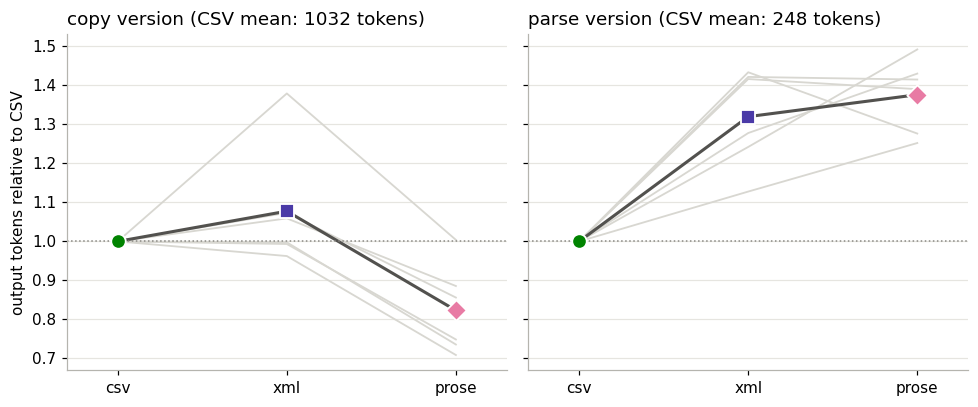

data_format  csv             xml             prose            
            mean  min  max  mean   min   max  mean   min   max
version                                                       
copy         1.0  1.0  1.0  1.08  0.96  1.38  0.82  0.71  1.00
parse        1.0  1.0  1.0  1.32  1.13  1.43  1.38  1.25  1.49

In [4]:
task_means = responses.groupby(["version", "task", "data_format"])["output_tokens"].mean().unstack()
relative = task_means.div(task_means["csv"], axis=0)[DATA_FORMATS]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
x = np.arange(len(DATA_FORMATS))
for ax, v in zip(axes, VERSIONS):
    rel = relative.loc[v]
    for _, row in rel.iterrows():
        ax.plot(x, row.values, color="#d8d7d1", linewidth=1.2, zorder=1)
    ax.plot(x, rel.mean().values, color="#52514e", linewidth=2, zorder=2)
    for i, d in enumerate(DATA_FORMATS):
        ax.scatter(i, rel[d].mean(), s=90, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=3,
                   edgecolor="white", linewidth=1.2)
    ax.axhline(1, color="#8a8984", linewidth=1, linestyle=":")
    ax.set_xticks(x, DATA_FORMATS)
    ax.set_xlim(-0.3, len(DATA_FORMATS) - 0.7)
    ax.set_title(f"{v} version (CSV mean: {task_means.loc[v, 'csv'].mean():.0f} tokens)", loc="left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("output tokens relative to CSV")
plt.tight_layout()
plt.show()

relative.groupby(level="version").agg(["mean", "min", "max"]).round(2)

## 4. Instruction style: structured vs informal

`eda1` pools the two instruction styles. Here they're compared directly, with the same permutation test (blocks: task × data format).

In [5]:
style_effects = pd.DataFrame([
    {"version": v, "data_format": d,
     **compare(responses[(responses["version"] == v) & (responses["data_format"] == d)],
               "structured", "informal", label_col="format", block_cols=("task", "data_format"))}
    for v in VERSIONS for d in DATA_FORMATS
]).set_index(["version", "data_format"])
style_means = responses.pivot_table(index=["version", "data_format"], columns="format",
                                    values="output_tokens", aggfunc="mean").round(0)
style_means.join(style_effects[["ratio", "p"]].round(3))

informal  structured  ratio      p
version data_format                                    
copy    csv            1038.0      1026.0  0.988  0.764
        prose           829.0       830.0  0.996  0.929
        xml            1082.0      1097.0  1.034  0.956
parse   csv             278.0       217.0  0.812  0.009
        prose           326.0       354.0  1.063  0.385
        xml             309.0       342.0  1.101  0.033

## 5. Run-to-run variability

For each prompt, the coefficient of variation (standard deviation / mean) of output tokens over its 5 runs. Higher means the same prompt gives less predictable token counts.

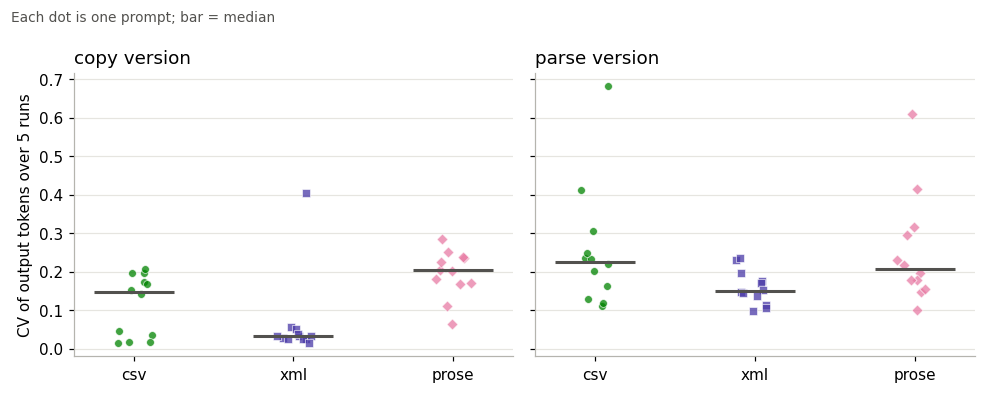

data_format,csv,xml,prose,Kruskal-Wallis p
version,,,,
copy,0.15,0.03,0.20,0.001
parse,0.23,0.15,0.21,0.054


In [6]:
cv = (responses.groupby(["version", "task", "format", "data_format"])["output_tokens"]
      .agg(lambda s: s.std() / s.mean()).rename("cv").reset_index())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
jitter = np.random.default_rng(SEED)
for ax, v in zip(axes, VERSIONS):
    for i, d in enumerate(DATA_FORMATS):
        vals = cv[(cv["version"] == v) & (cv["data_format"] == d)]["cv"]
        ax.scatter(i + jitter.uniform(-0.12, 0.12, len(vals)), vals, s=26, alpha=0.75, color=DATA_COLORS[d],
                   marker=DATA_MARKERS[d], edgecolor="white", linewidth=0.5)
        ax.hlines(vals.median(), i - 0.25, i + 0.25, color="#52514e", linewidth=2)
    ax.set_xticks(range(len(DATA_FORMATS)), DATA_FORMATS)
    ax.set_title(f"{v} version", loc="left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("CV of output tokens over 5 runs")
fig.suptitle("Each dot is one prompt; bar = median", x=0.01, ha="left", fontsize=9, color="#52514e")
plt.tight_layout()
plt.show()

cv_table = cv.groupby(["version", "data_format"])["cv"].median().unstack()[DATA_FORMATS].round(2)
cv_table["Kruskal-Wallis p"] = [
    stats.kruskal(*[cv[(cv["version"] == v) & (cv["data_format"] == d)]["cv"] for d in DATA_FORMATS]).pvalue
    for v in cv_table.index
]
cv_table.round(3)

## 6. Validity and the cost of a valid answer

Share of responses that passed both validity checks, with 95% Wilson intervals, and a chi-square test of whether validity depends on data format. **Tokens per valid response** = all tokens spent ÷ number of valid responses, i.e. the cost of retrying until a valid answer arrives.

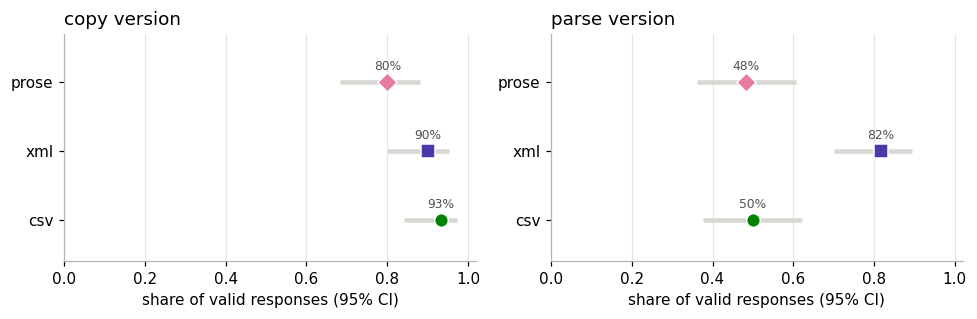

n  valid   rate    low   high  \
version data_format                                   
copy    csv          60     56  0.933  0.841  0.974   
        prose        60     48  0.800  0.682  0.882   
        xml          60     54  0.900  0.799  0.953   
parse   csv          60     30  0.500  0.377  0.623   
        prose        60     29  0.483  0.362  0.607   
        xml          60     49  0.817  0.701  0.894   

                     tokens per valid response  chi-square p (by version)  
version data_format                                                        
copy    csv                           1663.732                      0.068  
        prose                         1954.083                      0.068  
        xml                           2552.815                      0.068  
parse   csv                           1581.233                      0.000  
        prose                         2268.414                      0.000  
        xml                           1906.122                      0.000

In [7]:
def wilson(k, n, z=1.96):
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return center - half, center + half

validity = responses.groupby(["version", "data_format"]).agg(
    n=("passed_all", "size"), valid=("passed_all", "sum"), tokens=("total_tokens", "sum"))
validity["rate"] = validity["valid"] / validity["n"]
validity["low"], validity["high"] = wilson(validity["valid"], validity["n"])
validity["tokens per valid response"] = validity["tokens"] / validity["valid"]

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
for ax, v in zip(axes, VERSIONS):
    for i, d in enumerate(DATA_FORMATS):
        r = validity.loc[(v, d)]
        ax.hlines(i, r["low"], r["high"], color="#d8d7d1", linewidth=3, zorder=1)
        ax.scatter(r["rate"], i, s=80, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=2,
                   edgecolor="white", linewidth=1)
        ax.annotate(f"{r['rate']:.0%}", (r["rate"], i), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=8, color="#52514e")
    ax.set_yticks(range(len(DATA_FORMATS)), DATA_FORMATS)
    ax.set_ylim(-0.6, len(DATA_FORMATS) - 0.3)
    ax.set_xlim(0, 1.02)
    ax.set_title(f"{v} version", loc="left")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("share of valid responses (95% CI)")
plt.tight_layout()
plt.show()

validity["chi-square p (by version)"] = [
    stats.chi2_contingency(pd.crosstab(responses[responses["version"] == v]["data_format"],
                                       responses[responses["version"] == v]["passed_all"]))[1]
    for v, _ in validity.index
]
validity[["n", "valid", "rate", "low", "high", "tokens per valid response", "chi-square p (by version)"]].round(3)

In [8]:
# validity by instruction style
responses.pivot_table(index=["version", "data_format"], columns="format", values="passed_all", aggfunc="mean").round(2)

format               informal  structured
version data_format                      
copy    csv              0.90        0.97
        prose            0.73        0.87
        xml              0.80        1.00
parse   csv              0.57        0.43
        prose            0.50        0.47
        xml              0.87        0.77

## 7. Robustness: valid responses only

Section 2 repeated using only valid responses (as `eda1` does for the copy version). If the ratios barely move, the format effect isn't caused by invalid responses.

In [9]:
valid_only = responses[responses["passed_all"]]
pd.DataFrame([
    {"version": v, "comparison": f"{a} / {b}",
     "ratio (all)": effects.loc[(v, f"{a} / {b}"), "ratio"],
     **{k if k != "ratio" else "ratio (valid only)": val
        for k, val in compare(valid_only[valid_only["version"] == v], a, b).items()}}
    for v in VERSIONS for a, b in PAIRS
]).set_index(["version", "comparison"]).round(3)

ratio (all)  ratio (valid only)  95% CI low  95% CI high  \
version comparison                                                              
copy    xml / csv          1.067               1.103       1.016        1.219   
        prose / csv        0.810               0.825       0.742        0.933   
        xml / prose        1.316               1.338       1.280        1.402   
parse   xml / csv          1.360               1.254       1.138        1.348   
        prose / csv        1.392               1.189       1.080        1.309   
        xml / prose        0.977               1.066       0.987        1.166   

                         p  
version comparison          
copy    xml / csv    0.000  
        prose / csv  0.000  
        xml / prose  0.000  
parse   xml / csv    0.000  
        prose / csv  0.002  
        xml / prose  0.154

## Summary

- **Input is exact:** XML adds 26–43 tokens per data row over CSV (2.0–2.5× the input), prose 6–16 (1.2–1.6×). Structured instructions add about 25 input tokens.
- **Copy version:** prose gives about 19% fewer output tokens than CSV (p < 0.001; 5 of 6 tasks lower, one even). XML vs CSV is +7% and not clear: the task CI includes 1 and one task drives most of it.
- **Parse version, the effect flips:** XML (+36%) and prose (+39%) both need more output than CSV, in all 6 tasks (p < 0.001). XML and prose don't differ.
- **Instruction style** barely matters in the copy version; in the parse version the effects are small and mixed (CSV −19%, XML +10%).
- **Predictability:** copied XML output is very consistent across runs (median CV 0.03 vs 0.15 CSV, 0.20 prose). In the parse version the formats are closer (p = 0.05).
- **Validity:** copy 80–93%, no clear format difference (p = 0.07). Parse: XML 82% valid vs CSV 50% and prose 48% (p < 0.001).
- **Tokens per valid response:** CSV is cheapest in both versions (copy ≈ 1,660 vs prose 1,950, XML 2,550; parse ≈ 1,580 vs XML 1,910, prose 2,270). Prose's output savings in the copy version are cancelled by its longer input and lower validity.
- **Robustness:** with valid responses only, every direction holds; copy XML vs CSV becomes clear (+10%), and the parse gaps shrink to about +20–25%.
- **Limits:** 6 tasks, one model, 5 runs per prompt; the p-values treat the 6 tasks as fixed, so the task CIs are the better guide to generalizing.